# Proyek 3: DBSCAN Clustering dengan Cosine Similarity pada BISINDO

**Metrik Jarak:** Cosine Distance ($1 - \text{Cosine Similarity}$)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Target Klaster:** K = 26 Klaster Alfabet BISINDO  
**Parameter Terkalibrasi:** Epsilon = 0.0670, MinPts = 10  
**Output Target:** `outputDBScan/elbow_cosine.png`, `outputDBScan/cluster_cosine.png`, `outputDBScan/evaluasi_dbscan_cosine.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak Cosine mengukur deviasi sudut orientasi antarvektor gestur:
$$d_{\text{Cosine}}(x, y) = 1 - \frac{x \cdot y}{\|x\|_2 \|y\|_2}$$

Pada data yang telah dinormalisasi L2 ($\|x\|_2 = 1$), jarak sudut mengevaluasi bentuk pola konfigurasi jari tanpa terpengaruh oleh ukuran fisik telapak atau jarak tangan ke lensa kamera.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputDBScan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
EPS_COSINE = 0.0670
MIN_SAMPLES = 10
TARGET_CLUSTERS = 26

print(f"[INFO] Direktori: {BASE_DIR} | Epsilon = {EPS_COSINE} | MinPts = {MIN_SAMPLES}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan | Epsilon = 0.067 | MinPts = 10


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

normalizer = Normalizer(norm='l2')
X_norm = normalizer.fit_transform(X_std)
print("[INFO] Fitur dinormalisasi L2 ke permukaan bola satuan (||x|| = 1).")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur dinormalisasi L2 ke permukaan bola satuan (||x|| = 1).


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\elbow_cosine.png'


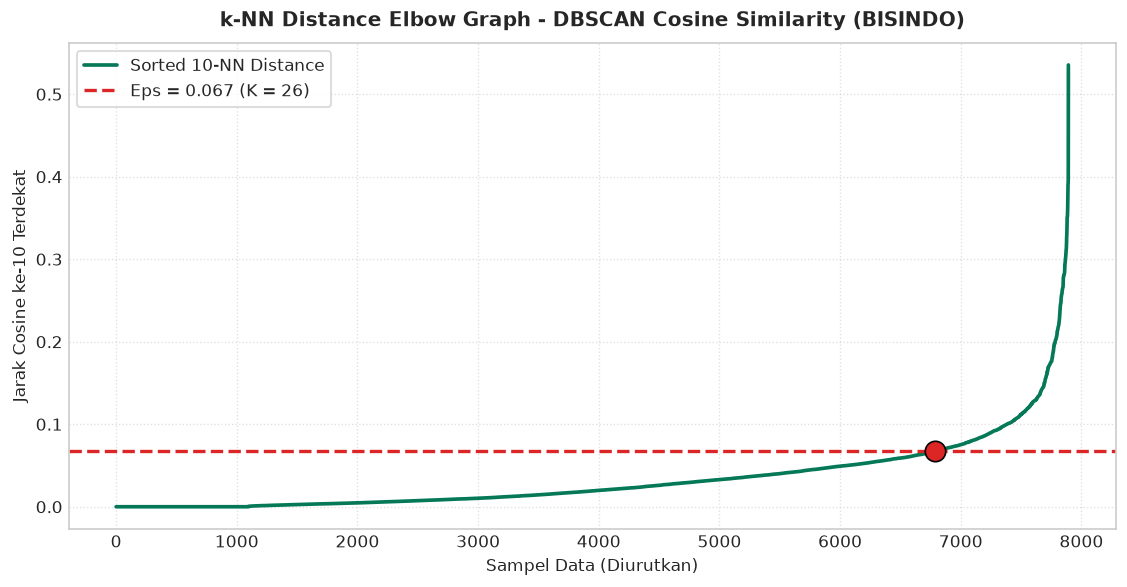

In [3]:
# =======================================================================
# 2. KURVA K-NN DISTANCE ELBOW COSINE
# =======================================================================
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='cosine')
nn.fit(X_norm)
dists, _ = nn.kneighbors(X_norm)
sorted_dists = np.sort(dists[:, -1])

plt.figure(figsize=(9.5, 5))
plt.plot(sorted_dists, color='#047857', linewidth=2.2, label=f'Sorted {MIN_SAMPLES}-NN Distance')
plt.axhline(y=EPS_COSINE, color='#DC2626', linestyle='--', linewidth=2, label=f'Eps = {EPS_COSINE} (K = 26)')

cut_idx = np.searchsorted(sorted_dists, EPS_COSINE)
plt.scatter([cut_idx], [EPS_COSINE], color='#DC2626', s=150, zorder=5, edgecolor='black')

plt.title('k-NN Distance Elbow Graph - DBSCAN Cosine Similarity (BISINDO)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Sampel Data (Diurutkan)', fontsize=10)
plt.ylabel(f'Jarak Cosine ke-{MIN_SAMPLES} Terdekat', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_cosine.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{elbow_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. PELATIHAN DBSCAN COSINE & EVALUASI METRIK
# =======================================================================
print(f"[PELATIHAN] Menjalankan DBSCAN Cosine (eps={EPS_COSINE}, min_samples={MIN_SAMPLES})...")
t0 = time.perf_counter()
model_cos = DBSCAN(eps=EPS_COSINE, min_samples=MIN_SAMPLES, metric='cosine').fit(X_norm)
runtime = time.perf_counter() - t0

labels = model_cos.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))
noise_pct = n_noise / len(labels) * 100
n_core = len(model_cos.core_sample_indices_)

mask = (labels != -1)
sil = float(silhouette_score(X_norm[mask], labels[mask], metric='cosine'))
db = float(davies_bouldin_score(X_norm[mask], labels[mask]))
ch = float(calinski_harabasz_score(X_norm[mask], labels[mask]))

df_res = pd.DataFrame([{
    'Distance Metric': 'Cosine Similarity (Spherical)',
    'Epsilon (eps)': EPS_COSINE,
    'Min Samples': MIN_SAMPLES,
    'Clusters Found': n_clusters,
    'Noise Samples (↓)': n_noise,
    'Noise Ratio (%) (↓)': round(noise_pct, 2),
    'Core Samples (↑)': n_core,
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(runtime, 4)
}])

print("\n" + "="*85)
print(df_res.to_string(index=False))
print("="*85)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_dbscan_cosine.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_cosine'] = labels

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")

[PELATIHAN] Menjalankan DBSCAN Cosine (eps=0.067, min_samples=10)...



              Distance Metric  Epsilon (eps)  Min Samples  Clusters Found  Noise Samples (↓)  Noise Ratio (%) (↓)  Core Samples (↑)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
Cosine Similarity (Spherical)          0.067           10              26                525                 6.65              6787               -0.1727                    1.0795                       234.06                  0.4717


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\evaluasi_dbscan_cosine.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\cluster_cosine.png'


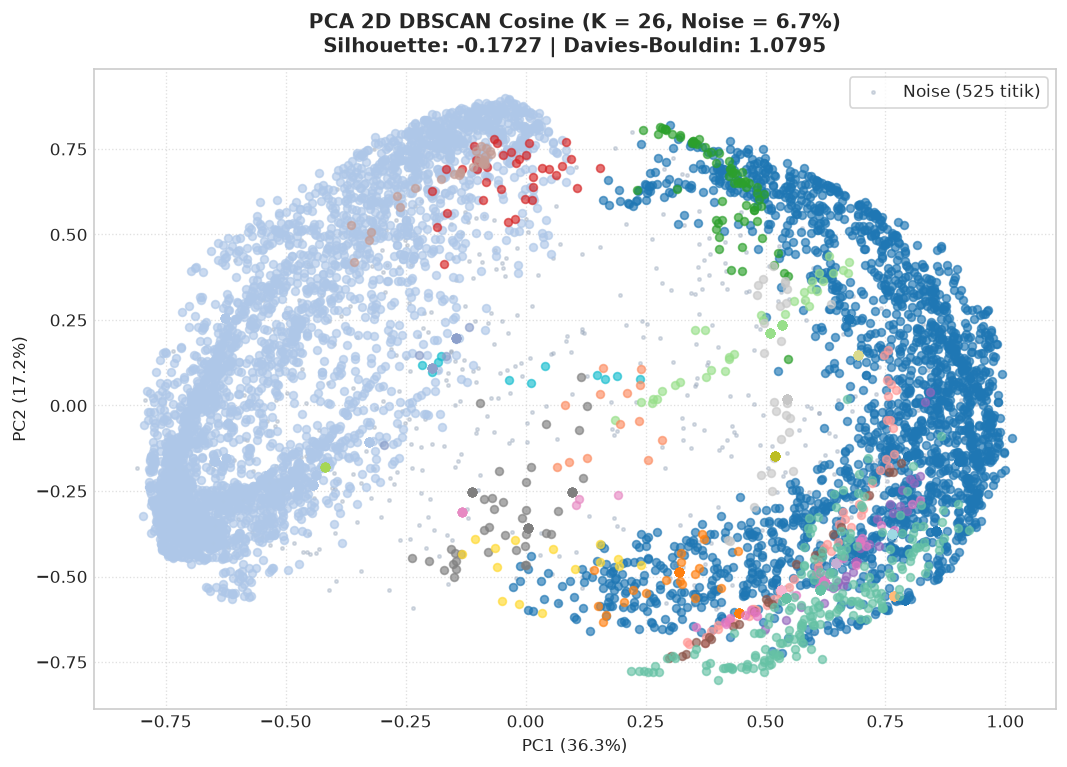

In [5]:
# =======================================================================
# 4. VISUALISASI PCA 2D DBSCAN COSINE
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_norm)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

noise_mask = (model_cos.labels_ == -1)
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], color='#94A3B8', label=f'Noise ({n_noise} titik)', alpha=0.35, s=16, marker='.')

for k in range(n_clusters):
    mask = (model_cos.labels_ == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.65, s=22)

plt.title(f'PCA 2D DBSCAN Cosine (K = {n_clusters}, Noise = {noise_pct:.1f}%)\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_cosine.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()